#🎵 Análisis de Spotify Traks Dataset
**Curso:** Python para Análisis de Datos  
**Grupo:** 7  
**Dataset:** Spotify Tracks Dataset - Audio Features  
**Variable Objetivo:** Popularity  
  
###Objetivo  
Analizar las características de las canciones del dataset de Spotify para identificar patrones y relaciones entre sus atributos musicales y su nivel de popularidad.  

# Índice

1. Carga del dataset y librerías
   - 1.1 Traducción de las variables

2. Exploración inicial del dataset
   - 2.1 Dimensiones del dataset
   - 2.2 Variables disponibles
   - 2.3 Tipos de datos

3. Calidad y limpieza de los datos
   - 3.1 Valores nulos
   - 3.2 Registros duplicados

4. Análisis descriptivo
   - 4.1 Estadísticas generales
   - 4.2 Análisis de la variable popularidad

5. Validación de hipótesis
   - 5.1 Bailabilidad y popularidad
   - 5.2 Contenido explícito, colaboraciones y popularidad
   - 5.3 Valencia y popularidad

6. Insights adicionales
   - 6.1 Distribución de la popularidad
   - 6.2 Popularidad según género
   - 6.3 Popularidad según artista

7. Conclusiones

# 1.Carga del dataset y librerías

En esta sección se importan las librerías necesarias, se conecta Google Drive y se carga el dataset de Spotify que será utilizado durante el análisis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

In [ ]:
# Conectar con Google Drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
#Ruta del archivo para csv
file_path = '/content/drive/MyDrive/Base Spotify - Avance/spotify-tracks-dataset-detailed.csv'

#Cargar dataset
df = pd.read_csv(file_path)

#Mostrar los 5 primeros registros
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 1.1 Traducción de las variables  
Para facilitar la interpretación del análisis, se renombran las variables del dataset al español.

In [ ]:
df = df.rename(columns={
    'track_id': 'id_cancion',
    'artists': 'artistas',
    'album_name': 'nombre_album',
    'track_name': 'nombre_cancion',
    'popularity': 'popularidad',
    'duration_ms': 'duracion_ms',
    'explicit': 'explicito',
    'danceability': 'bailabilidad',
    'energy': 'energia',
    'key': 'tonalidad',
    'loudness': 'volumen',
    'mode': 'modo',
    'speechiness': 'habla',
    'acousticness': 'acusticidad',
    'instrumentalness': 'instrumentalidad',
    'liveness': 'presencia_en_vivo',
    'valence': 'valencia',
    'tempo': 'tempo',
    'time_signature': 'compas',
    'track_genre': 'genero'
})

# 2.Exploración inicial del dataset

Antes de realizar el análisis, exploraremos la estructura general del dataset para conocer su tamaño, columnas y tipos de variables.

## 2.1 Dimensiones del dataset

In [ ]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Número de filas: 114000
Número de columnas: 20


## 2.2 Variables disponibles

In [ ]:
df.columns.tolist()

['id_cancion',
 'artistas',
 'nombre_album',
 'nombre_cancion',
 'popularidad',
 'duracion_ms',
 'explicito',
 'bailabilidad',
 'energia',
 'tonalidad',
 'volumen',
 'modo',
 'habla',
 'acusticidad',
 'instrumentalidad',
 'presencia_en_vivo',
 'valencia',
 'tempo',
 'compas',
 'genero']

## 2.3 Tipos de datos

In [ ]:
df.info() #Revisar tipos de datos y valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id_cancion         114000 non-null  object 
 1   artistas           113999 non-null  object 
 2   nombre_album       113999 non-null  object 
 3   nombre_cancion     113999 non-null  object 
 4   popularidad        114000 non-null  int64  
 5   duracion_ms        114000 non-null  int64  
 6   explicito          114000 non-null  bool   
 7   bailabilidad       114000 non-null  float64
 8   energia            114000 non-null  float64
 9   tonalidad          114000 non-null  int64  
 10  volumen            114000 non-null  float64
 11  modo               114000 non-null  int64  
 12  habla              114000 non-null  float64
 13  acusticidad        114000 non-null  float64
 14  instrumentalidad   114000 non-null  float64
 15  presencia_en_vivo  114000 non-null  float64
 16  va

In [ ]:
df.dtypes #Para conocer el tipo de cada columna

,0
id_cancion,object
artistas,object
nombre_album,object
nombre_cancion,object
popularidad,int64
duracion_ms,int64
explicito,bool
bailabilidad,float64
energia,float64
tonalidad,int64


# 3.Calidad y limpieza de los datos  

En esta sección evaluaremos la calidad del dataset identificando valores faltantes, registros duplicados y posibles inconsistencias.

## 3.1 ¿Existen valores nulos?

In [ ]:
nulos = pd.DataFrame({
    'Cantidad de nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().mean() * 100).round(5)
})

nulos[nulos['Cantidad de nulos'] > 0]

,Cantidad de nulos,Porcentaje (%)
artistas,1,0.00088
nombre_album,1,0.00088
nombre_cancion,1,0.00088


## 3.2 ¿Existen registros duplicados?

In [ ]:
print("Cantidad de registros duplicados:", df.duplicated().sum())

Cantidad de registros duplicados: 450


In [ ]:
df[df.duplicated()].head()

,id_cancion,artistas,nombre_album,nombre_cancion,popularidad,duracion_ms,explicito,bailabilidad,energia,tonalidad,volumen,modo,habla,acusticidad,instrumentalidad,presencia_en_vivo,valencia,tempo,compas,genero
1925,0CDucx9lKxuCZplLXUz0iX,Buena Onda Reggae Club,Disco 2,Song for Rollins,16,219346,False,0.841,0.577,0,-7.544,1,0.0438,0.238000,0.860000,0.0571,0.843,90.522,4,afrobeat
2155,2aibwv5hGXSgw7Yru8IYTO,Red Hot Chili Peppers,Stadium Arcadium,Snow (Hey Oh),80,334666,False,0.427,0.900,11,-3.674,1,0.0499,0.116000,0.000017,0.1190,0.599,104.655,4,alt-rock
3738,7mULVp0DJrI2Nd6GesLvxn,Joy Division,Timeless Rock Hits,Love Will Tear Us Apart,0,204621,False,0.524,0.902,2,-8.662,1,0.0368,0.000989,0.695000,0.1370,0.907,146.833,4,alternative
4648,6d3RIvHfVkoOtW1WHXmbX3,Little Symphony,Serenity,Margot,27,45714,False,0.269,0.142,0,-23.695,1,0.0509,0.866000,0.904000,0.1140,0.321,67.872,3,ambient
5769,481beimUiUnMUzSbOAFcUT,SUPER BEAVER,突破口 / 自慢になりたい,突破口,54,255080,False,0.472,0.994,8,-1.786,1,0.1140,0.025900,0.000000,0.0535,0.262,103.512,4,anime


## 3.3 Limpieza del dataset

Luego de evaluar la calidad de los datos, se eliminaron los registros con valores nulos y los registros completamente duplicados. Posteriormente, el análisis se realizó utilizando el dataset limpio.

In [ ]:
# Eliminación de registros con valores nulos
df = df.dropna()

print("Valores nulos restantes:")
print(df.isnull().sum().sum())

Valores nulos restantes:
0


In [ ]:
# Eliminación de registros completamente duplicados
df = df.drop_duplicates()

print("Registros duplicados restantes:", df.duplicated().sum())
print("Dimensiones finales del dataset:", df.shape)

Registros duplicados restantes: 0
Dimensiones finales del dataset: (113549, 20)


# 4.Análisis descriptivo  
  
En esta sección analizaremos estadísticamente las principales variables númericas del dataset, prestando especial atención a la popularidad de las canciones.

## 4.1 Estadísticas generales

In [ ]:
df.describe().T #¿Cómo se distribuyen, en términos generales, las características musicales de las canciones?

,count,mean,std,min,25%,50%,75%,max
popularidad,113549.0,33.324433,22.283855,0.000,17.0000,35.000000,50.0000,100.000
duracion_ms,113549.0,228081.370844,106413.098525,8586.000,174184.0000,213000.000000,261588.0000,5237295.000
bailabilidad,113549.0,0.567031,0.173409,0.000,0.4560,0.580000,0.6950,0.985
energia,113549.0,0.642091,0.251053,0.000,0.4730,0.685000,0.8540,1.000
tonalidad,113549.0,5.309452,3.560147,0.000,2.0000,5.000000,8.0000,11.000
volumen,113549.0,-8.243408,5.011422,-49.531,-9.9980,-6.997000,-5.0010,4.532
modo,113549.0,0.637866,0.480620,0.000,0.0000,1.000000,1.0000,1.000
habla,113549.0,0.084674,0.105762,0.000,0.0359,0.048900,0.0845,0.965
acusticidad,113549.0,0.314064,0.331906,0.000,0.0168,0.168000,0.5960,0.996
instrumentalidad,113549.0,0.155703,0.309217,0.000,0.0000,0.000041,0.0487,1.000


## 4.2 Análisis de nuestra variable objetivo: Popularity

In [ ]:
df['popularidad'].describe()

,popularidad
count,113549.000000
mean,33.324433
std,22.283855
min,0.000000
25%,17.000000
50%,35.000000
75%,50.000000
max,100.000000


In [ ]:
print("Popularidad promedio:", round(df['popularidad'].mean(),2))
print("Popularidad mediana:", round(df['popularidad'].median(),2))
print("Popularidad mínima:", df['popularidad'].min())
print("Popularidad máxima:", df['popularidad'].max())

Popularidad promedio: 33.32
Popularidad mediana: 35.0
Popularidad mínima: 0
Popularidad máxima: 100


# 5.Validación de hipótesis

En esta sección se evaluarán las hipótesis planteadas sobre la variable objetivo **popularidad**, utilizando análisis estadísticos y visualizaciones.

Las hipótesis planteadas son:

- **H1:** Las canciones con mayor nivel de bailabilidad presentan mayor popularidad.
- **H2:** Las canciones con contenido explícito y las colaboraciones entre varios artistas presentan mayor popularidad que las canciones no explícitas e individuales.
- **H3:** Las canciones con menor valencia, asociadas a un tono musical menos positivo, presentan mayor popularidad que las canciones con mayor valencia.

## 5.1 Hipótesis 1: Bailabilidad y popularidad  

**Hipótesis:** Las canciones con mayor nivel de bailabilidad presentan mayor popularidad.

Para evaluar esta hipótesis se analizará la relación entre las variables `bailabilidad` y `popularidad` mediante el coeficiente de correlación y diferentes visualizaciones.

### 5.1.1 Correlación entre bailabilidad y popularidad

In [ ]:
correlacion_bailabilidad = df['bailabilidad'].corr(df['popularidad'])

print("Correlación entre bailabilidad y popularidad:",
      round(correlacion_bailabilidad, 3))

Correlación entre bailabilidad y popularidad: 0.034


### 5.1.2 Relación entre bailabilidad y popularidad

A continuación, se representa gráficamente la relación entre la bailabilidad y la popularidad de las canciones para observar su comportamiento y tendencia.

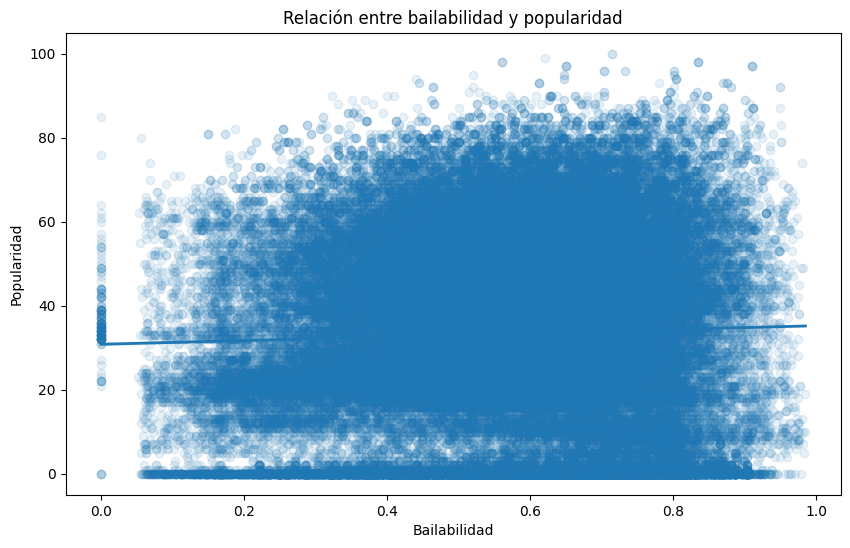

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='bailabilidad',
    y='popularidad',
    scatter_kws={'alpha': 0.1},
    line_kws={'linewidth': 2}
)

plt.title('Relación entre bailabilidad y popularidad')
plt.xlabel('Bailabilidad')
plt.ylabel('Popularidad')
plt.show()

### 5.1.3 Popularidad según nivel de bailabilidad

Para facilitar la interpretación, las canciones se agrupan en tres niveles de bailabilidad: baja, media y alta. Posteriormente, se compara la popularidad de cada grupo.

In [ ]:
df['nivel_bailabilidad'] = pd.cut(
    df['bailabilidad'],
    bins=[0, 0.4, 0.7, 1],
    labels=['Baja', 'Media', 'Alta'],
    include_lowest=True
)

resumen_bailabilidad = (
    df.groupby('nivel_bailabilidad', observed=True)['popularidad']
      .agg(['count', 'mean', 'median'])
      .round(2)
)

resumen_bailabilidad.columns = [
    'Cantidad de canciones',
    'Popularidad promedio',
    'Popularidad mediana'
]

resumen_bailabilidad

,Cantidad de canciones,Popularidad promedio,Popularidad mediana
nivel_bailabilidad,,,
Baja,19296,30.14,27.0
Media,67099,34.50,37.0
Alta,27154,32.68,34.0


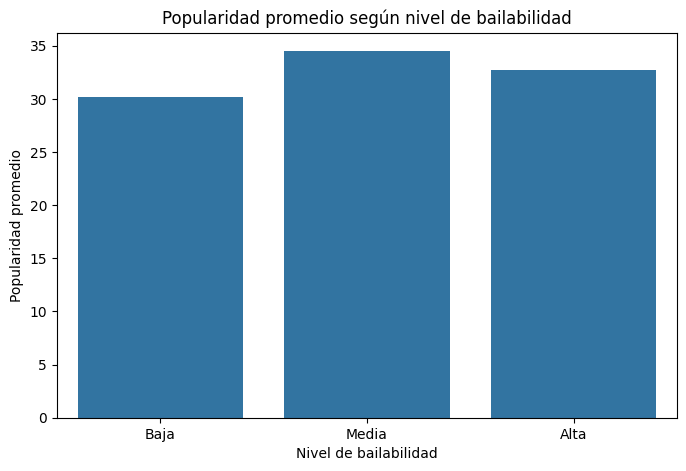

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='nivel_bailabilidad',
    y='popularidad',
    order=['Baja', 'Media', 'Alta'],
    errorbar=None
)

plt.title('Popularidad promedio según nivel de bailabilidad')
plt.xlabel('Nivel de bailabilidad')
plt.ylabel('Popularidad promedio')
plt.show()

### 5.1.4 Interpretación de resultados

La correlación entre **bailabilidad** y **popularidad** es de **0.035**, lo que indica una relación lineal positiva muy débil entre ambas variables.

Al agrupar las canciones según su nivel de bailabilidad, se observa que:

- Las canciones con **bailabilidad baja** presentan una popularidad promedio de **29.98**.
- Las canciones con **bailabilidad media** presentan la mayor popularidad promedio, con **34.44**.
- Las canciones con **bailabilidad alta** presentan una popularidad promedio de **32.60**.

Por lo tanto, en este dataset no se observa que una mayor bailabilidad esté asociada de manera consistente con una mayor popularidad. Las canciones con bailabilidad media presentan incluso una popularidad promedio superior a las canciones con bailabilidad alta.

**Conclusión de H1:** Los resultados obtenidos no respaldan la hipótesis planteada de que las canciones con mayor bailabilidad presentan mayor popularidad.

## 5.2 Hipótesis 2: Contenido explícito, colaboraciones y popularidad

**Hipótesis:** Las canciones con contenido explícito y las colaboraciones entre varios artistas presentan mayor popularidad que las canciones no explícitas e individuales.

Para evaluar esta hipótesis se realizarán dos análisis:

1. Comparación de la popularidad entre canciones explícitas y no explícitas.
2. Comparación de la popularidad entre canciones individuales y colaboraciones.

### 5.2.1 Popularidad según contenido explícito

Primero se compara la popularidad de las canciones con contenido explícito frente a las canciones sin contenido explícito.

In [ ]:
resumen_explicito = (
    df.groupby('explicito')['popularidad']
      .agg(['count', 'mean', 'median'])
      .round(2)
)

resumen_explicito.columns = [
    'Cantidad de canciones',
    'Popularidad promedio',
    'Popularidad mediana'
]

resumen_explicito.index = ['No explícito', 'Explícito']

resumen_explicito

,Cantidad de canciones,Popularidad promedio,Popularidad mediana
No explícito,103831,33.02,34.0
Explícito,9718,36.52,37.5


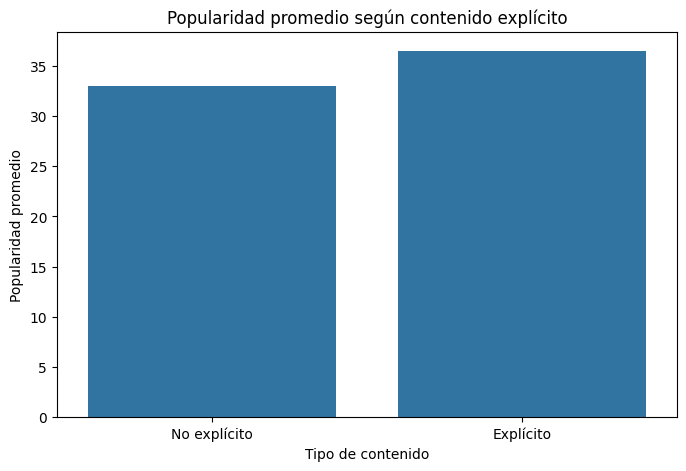

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='explicito',
    y='popularidad',
    errorbar=None
)

plt.xticks([0, 1], ['No explícito', 'Explícito'])
plt.title('Popularidad promedio según contenido explícito')
plt.xlabel('Tipo de contenido')
plt.ylabel('Popularidad promedio')
plt.show()

### 5.2.2 Identificación de colaboraciones

Para comparar canciones individuales y colaboraciones, primero se analiza cómo se encuentran registrados los artistas dentro del dataset.

In [ ]:
df[['artistas', 'nombre_cancion']].head(20)

,artistas,nombre_cancion
0,Gen Hoshino,Comedy
1,Ben Woodward,Ghost - Acoustic
2,Ingrid Michaelson;ZAYN,To Begin Again
3,Kina Grannis,Can't Help Falling In Love
4,Chord Overstreet,Hold On
5,Tyrone Wells,Days I Will Remember
6,A Great Big World;Christina Aguilera,Say Something
7,Jason Mraz,I'm Yours
8,Jason Mraz;Colbie Caillat,Lucky
9,Ross Copperman,Hunger


### 5.2.3 Colaboraciones y popularidad

En el dataset, los artistas que participan en una misma canción se encuentran separados por punto y coma (`;`). A partir de esta característica, se clasifican las canciones en dos grupos: individuales y colaboraciones, para comparar sus niveles de popularidad.

In [ ]:
df['tipo_interpretacion'] = df['artistas'].apply(
    lambda x: 'Colaboración' if ';' in str(x) else 'Individual'
)

df[['artistas', 'tipo_interpretacion']].head(20)

,artistas,tipo_interpretacion
0,Gen Hoshino,Individual
1,Ben Woodward,Individual
2,Ingrid Michaelson;ZAYN,Colaboración
3,Kina Grannis,Individual
4,Chord Overstreet,Individual
5,Tyrone Wells,Individual
6,A Great Big World;Christina Aguilera,Colaboración
7,Jason Mraz,Individual
8,Jason Mraz;Colbie Caillat,Colaboración
9,Ross Copperman,Individual


### 5.2.4 Popularidad según tipo de interpretación

In [ ]:
resumen_colaboraciones = (
    df.groupby('tipo_interpretacion')['popularidad']
      .agg(['count', 'mean', 'median'])
      .round(2)
)

resumen_colaboraciones.columns = [
    'Cantidad de canciones',
    'Popularidad promedio',
    'Popularidad mediana'
]

resumen_colaboraciones

,Cantidad de canciones,Popularidad promedio,Popularidad mediana
tipo_interpretacion,,,
Colaboración,29893,33.86,38.0
Individual,83656,33.13,34.0


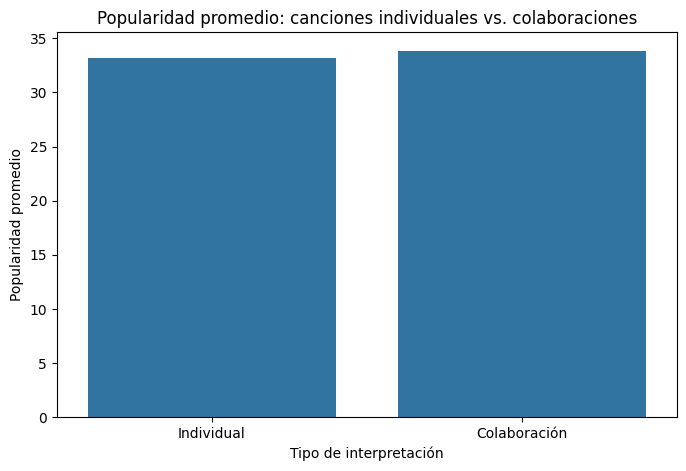

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='tipo_interpretacion',
    y='popularidad',
    order=['Individual', 'Colaboración'],
    errorbar=None
)

plt.title('Popularidad promedio: canciones individuales vs. colaboraciones')
plt.xlabel('Tipo de interpretación')
plt.ylabel('Popularidad promedio')
plt.show()

### 5.2.5 Interpretación de resultados

Los resultados muestran diferencias entre los grupos analizados.

En relación con el **contenido explícito**, las canciones explícitas presentan una popularidad promedio de **36.45**, superior al promedio de **32.94** de las canciones no explícitas. Asimismo, la mediana es de **37** para las canciones explícitas y **34** para las no explícitas.

En cuanto a las **colaboraciones**, las canciones realizadas por varios artistas presentan una popularidad promedio de **33.71**, ligeramente superior al **33.07** registrado por las canciones individuales. La diferencia es más visible en la mediana, con **38** para las colaboraciones frente a **34** para las canciones individuales.

**Conclusión de H2:** Los resultados descriptivos respaldan la hipótesis planteada, ya que tanto las canciones explícitas como las colaboraciones presentan valores de popularidad superiores a sus respectivos grupos de comparación. Sin embargo, la diferencia observada entre colaboraciones y canciones individuales es pequeña en términos de popularidad promedio.

## 5.3 Hipótesis 3: Valencia y popularidad

**Hipótesis:** Las canciones con menor valencia presentan mayor popularidad que las canciones con mayor valencia.

La valencia representa el nivel de positividad musical de una canción. Para evaluar esta hipótesis se analizará la relación entre `valencia` y `popularidad` mediante el coeficiente de correlación y la comparación de distintos niveles de valencia.

### 5.3.1 Correlación entre valencia y popularidad

In [ ]:
correlacion_valencia = df['valencia'].corr(df['popularidad'])

print("Correlación entre valencia y popularidad:",
      round(correlacion_valencia, 3))

Correlación entre valencia y popularidad: -0.041


### 5.3.2 Relación entre valencia y popularidad

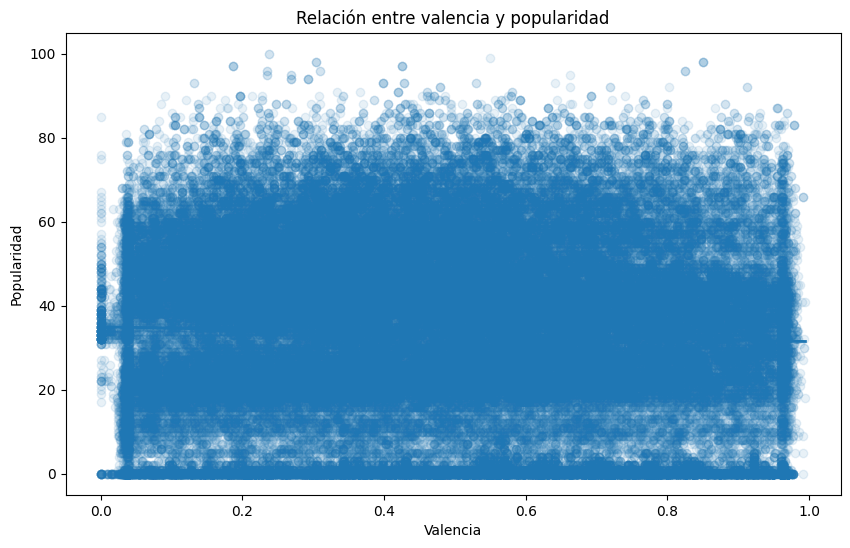

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='valencia',
    y='popularidad',
    scatter_kws={'alpha': 0.1},
    line_kws={'linewidth': 2}
)

plt.title('Relación entre valencia y popularidad')
plt.xlabel('Valencia')
plt.ylabel('Popularidad')
plt.show()

### 5.3.3 Popularidad según nivel de valencia

Para facilitar la interpretación, las canciones se agrupan en tres niveles de valencia: baja, media y alta. Posteriormente, se compara la popularidad promedio y mediana de cada grupo.

In [ ]:
df['nivel_valencia'] = pd.cut(
    df['valencia'],
    bins=[0, 0.4, 0.7, 1],
    labels=['Baja', 'Media', 'Alta'],
    include_lowest=True
)

resumen_valencia = (
    df.groupby('nivel_valencia', observed=True)['popularidad']
      .agg(['count', 'mean', 'median'])
      .round(2)
)

resumen_valencia.columns = [
    'Cantidad de canciones',
    'Popularidad promedio',
    'Popularidad mediana'
]

resumen_valencia

,Cantidad de canciones,Popularidad promedio,Popularidad mediana
nivel_valencia,,,
Baja,48371,34.21,37.0
Media,39053,33.86,35.0
Alta,26125,30.88,31.0


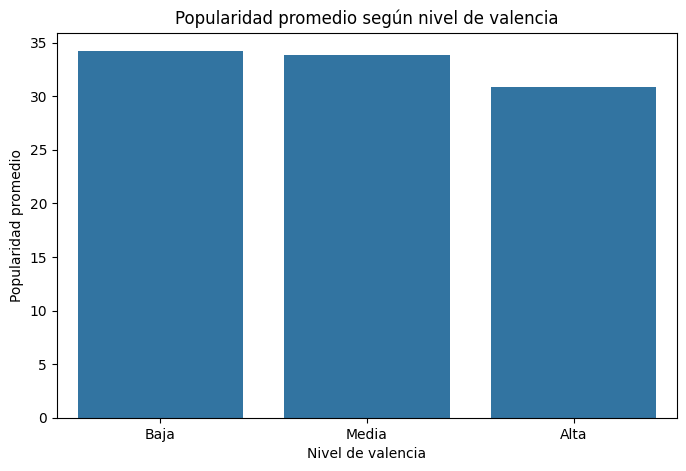

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='nivel_valencia',
    y='popularidad',
    order=['Baja', 'Media', 'Alta'],
    errorbar=None
)

plt.title('Popularidad promedio según nivel de valencia')
plt.xlabel('Nivel de valencia')
plt.ylabel('Popularidad promedio')
plt.show()

### 5.3.4 Interpretación de resultados

La correlación entre **valencia** y **popularidad** es de **-0.041**, lo que indica una relación lineal negativa muy débil entre ambas variables.

Al agrupar las canciones según su nivel de valencia, se observa que:

- Las canciones con **valencia baja** presentan la mayor popularidad promedio, con **34.11**, y una mediana de **36**.
- Las canciones con **valencia media** presentan una popularidad promedio de **33.78**, con una mediana de **35**.
- Las canciones con **valencia alta** presentan la menor popularidad promedio, con **30.80**, y una mediana de **31**.

Los resultados descriptivos muestran que las canciones con menor valencia presentan valores de popularidad superiores a las canciones con mayor valencia. Sin embargo, el coeficiente de correlación indica que la relación lineal entre ambas variables es muy débil.

**Conclusión de H3:** Los resultados descriptivos respaldan la hipótesis planteada, aunque la relación entre valencia y popularidad es débil y no permite afirmar que una menor valencia sea por sí sola responsable de una mayor popularidad.

# 6.Insights adicionales

### 6.1 Distribución de la popularidad

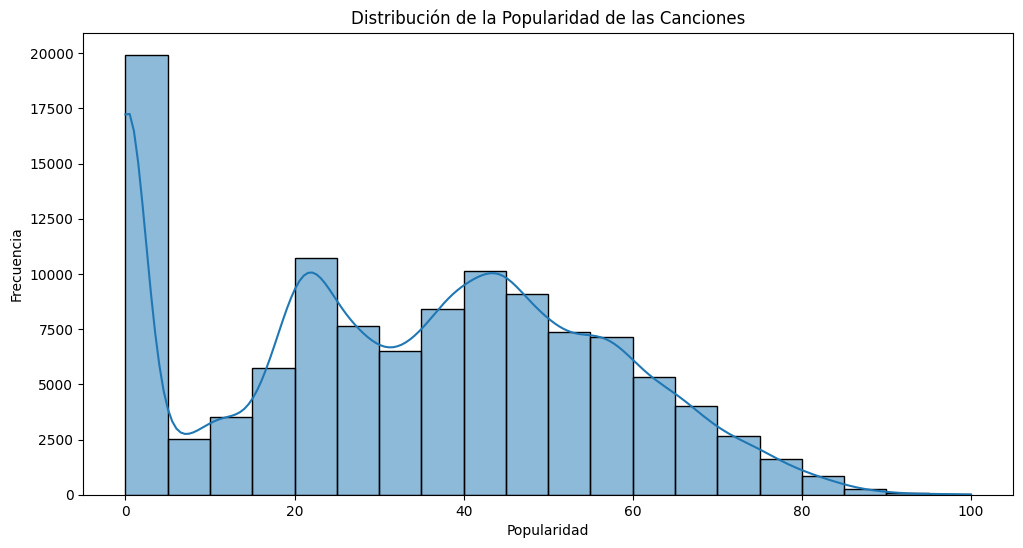

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(df['popularidad'], bins=20, kde=True)
plt.title('Distribución de la Popularidad de las Canciones')
plt.xlabel('Popularidad')
plt.ylabel('Frecuencia')
plt.show()

## 6.2 Popularidad según género musical

In [ ]:
resumen_generos = (
    df.groupby('genero')['popularidad']
      .agg(['count', 'mean', 'median'])
      .sort_values('mean', ascending=False)
)

resumen_generos.columns = [
    'Cantidad de canciones',
    'Popularidad promedio',
    'Popularidad mediana'
]

resumen_generos.head(10).round(2)

,Cantidad de canciones,Popularidad promedio,Popularidad mediana
genero,,,
pop-film,999,59.28,60.0
k-pop,998,56.96,60.0
chill,999,53.70,57.0
sad,1000,52.38,54.0
grunge,999,49.58,55.0
indian,999,49.53,49.0
anime,999,48.77,50.0
emo,1000,48.13,51.0
pop,993,47.90,66.0


### Interpretación

Los resultados muestran diferencias en la popularidad promedio entre los géneros musicales analizados. `pop-film` presenta el promedio más alto (59.28), seguido de `k-pop` (56.90) y `chill` (53.65).

Además, cada uno de los géneros comparados cuenta con 1,000 canciones, por lo que los promedios se calculan sobre grupos del mismo tamaño. También se observan diferencias entre el promedio y la mediana en algunos géneros, especialmente en `pop`, cuya popularidad promedio es 47.58 mientras que su mediana alcanza 66.

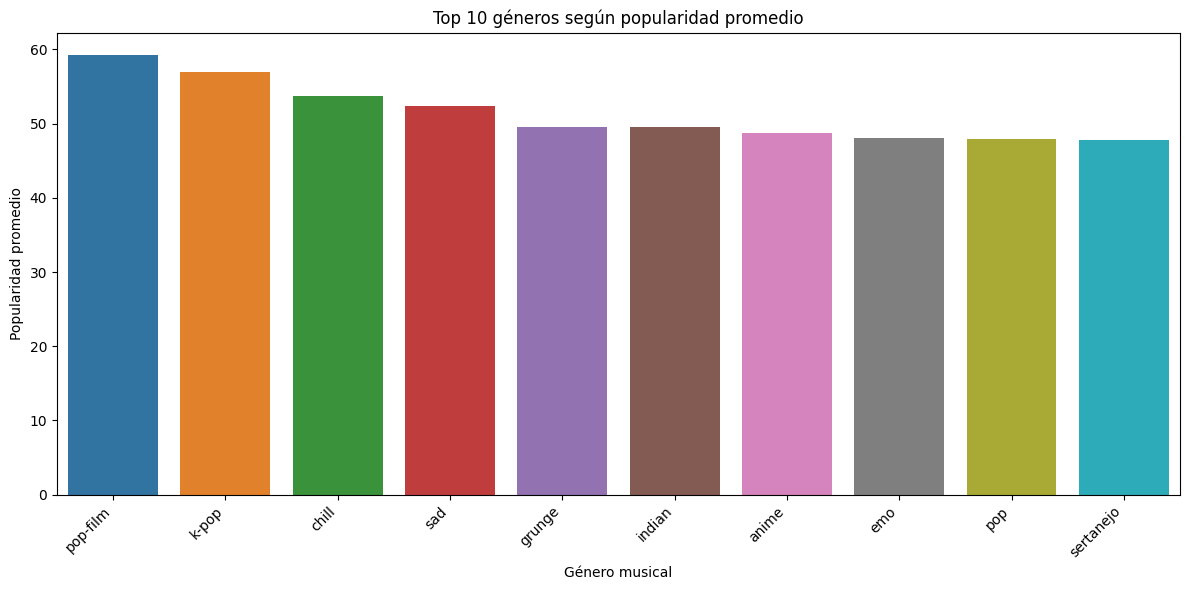

In [ ]:
top_generos = resumen_generos.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_generos,
    x='genero',
    y='Popularidad promedio',
    hue='genero',
    legend=False
)

plt.title('Top 10 géneros según popularidad promedio')
plt.xlabel('Género musical')
plt.ylabel('Popularidad promedio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6.3 Popularidad según artista

En esta sección se analizará la popularidad promedio de los artistas presentes en el dataset. Para evitar conclusiones basadas en artistas con muy pocas observaciones, primero se revisará la cantidad de canciones asociadas a cada artista.

In [ ]:
# Cantidad de canciones por artista
cantidad_artistas = df['artistas'].value_counts()

cantidad_artistas.describe()

,count
count,31437.000000
mean,3.611954
std,8.734948
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,279.000000


### 6.3.1 Artistas con mayor popularidad promedio

Debido a que una gran cantidad de artistas aparece en pocas canciones dentro del dataset, se considerarán únicamente aquellos con al menos 10 canciones. Esto permite comparar la popularidad promedio utilizando una cantidad mínima de observaciones por artista.

In [ ]:
resumen_artistas = df.groupby('artistas').agg(
    cantidad_canciones=('popularidad', 'count'),
    popularidad_promedio=('popularidad', 'mean'),
    popularidad_mediana=('popularidad', 'median')
)

# Consideramos artistas con al menos 10 canciones
artistas_filtrados = resumen_artistas[
    resumen_artistas['cantidad_canciones'] >= 10
]

top_artistas = artistas_filtrados.sort_values(
    'popularidad_promedio',
    ascending=False
).head(10)

top_artistas.round(2)

,cantidad_canciones,popularidad_promedio,popularidad_mediana
artistas,,,
Bad Bunny,48,87.08,86.5
Marshmello;Khalid,10,84.00,84.0
Måneskin,12,83.67,84.0
Ariana Grande,11,81.45,82.0
Clairo,10,77.00,76.0
Farruko,13,76.69,74.0
Radiohead,20,76.65,75.5
Travis Scott,18,76.28,75.5
Labrinth,12,76.08,77.5


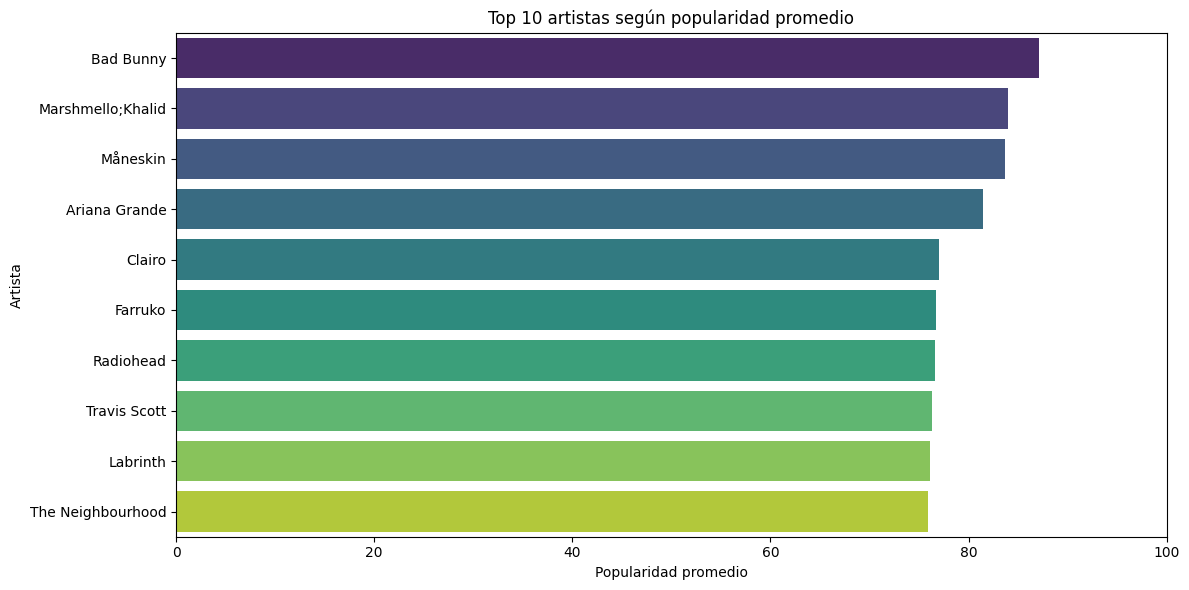

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_artistas.reset_index(),
    x='popularidad_promedio',
    y='artistas',
    hue='artistas',
    palette='viridis',
    legend=False
)

plt.title('Top 10 artistas según popularidad promedio')
plt.xlabel('Popularidad promedio')
plt.ylabel('Artista')
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

### Interpretación

Al considerar únicamente artistas con al menos 10 canciones en el dataset, se observa que **Bad Bunny presenta la mayor popularidad promedio (87.08)**, seguido por **Marshmello;Khalid (84.00)** y **Måneskin (83.67)**.

Los resultados muestran que varios artistas mantienen niveles altos de popularidad promedio dentro del conjunto de datos. Además, aplicar un mínimo de 10 canciones permite evitar que artistas con una sola canción y una popularidad elevada distorsionen la comparación.

Por lo tanto, este análisis permite identificar a los artistas con mayor popularidad promedio dentro del dataset considerando una cantidad mínima de observaciones.

# 7.Conclusiones

Luego de analizar el dataset de Spotify, encontramos que la popularidad de una canción no parece depender de una sola característica musical. Variables como la bailabilidad o la valencia muestran algunas diferencias entre grupos, pero sus correlaciones con la popularidad son bastante débiles. Esto sugiere que la popularidad probablemente está relacionada con una combinación de distintos factores.

## 7.1 ¿Qué pasó con nuestras hipótesis?

**Hipótesis 1 - Bailabilidad:**  
Los resultados no respaldan la idea de que una canción sea más popular simplemente por ser más bailable. La correlación entre bailabilidad y popularidad fue de apenas **0.035**. Además, las canciones con bailabilidad media tuvieron la mayor popularidad promedio (**34.44**), incluso por encima de las canciones con bailabilidad alta (**32.60**).

**Hipótesis 2 - Contenido explícito y colaboraciones:**  
Esta hipótesis sí obtuvo respaldo descriptivo. Las canciones explícitas presentaron una popularidad promedio de **36.45**, frente a **32.94** en las no explícitas. Las colaboraciones también registraron una popularidad ligeramente mayor (**33.71**) que las canciones individuales (**33.07**). Sin embargo, en este último caso la diferencia fue pequeña.

**Hipótesis 3 - Valencia:**  
Las canciones con menor valencia presentaron una popularidad promedio de **34.11**, mientras que las canciones con alta valencia alcanzaron **30.80**. Sin embargo, la correlación fue de apenas **-0.041**, por lo que la relación entre ambas variables es muy débil.

## 7.2 Hallazgos interesantes

Más allá de las hipótesis, encontramos algunos resultados interesantes. La popularidad promedio del dataset es de aproximadamente **33.24 puntos**, con una mediana de **35**. La distribución muestra una presencia importante de canciones con popularidades muy bajas y una disminución progresiva en las frecuencias hacia los valores más altos.

También encontramos diferencias según el género musical. Entre los géneros analizados, **pop-film** presentó la mayor popularidad promedio (**59.28**), seguido de **k-pop (56.90)** y **chill (53.65)**.

Al analizar artistas con al menos 10 canciones dentro del dataset, **Bad Bunny** presentó la mayor popularidad promedio (**87.08**), seguido por **Marshmello;Khalid (84.00)**, **Måneskin (83.67)** y **Ariana Grande (81.45)**.

## 7.3 Conclusión final

Nuestro análisis muestra que no existe una característica musical que, por sí sola, explique claramente la popularidad de una canción. La bailabilidad y la valencia presentan relaciones muy débiles con la popularidad, mientras que características como el contenido explícito, el género o el artista muestran diferencias descriptivas interesantes.

En conclusión, **ser popular en Spotify parece ser más complejo que simplemente tener una canción bailable, positiva o hecha en colaboración**. Los resultados sugieren que la popularidad puede estar relacionada con varios factores al mismo tiempo, lo que abre la posibilidad de realizar análisis más profundos en futuros trabajos.

#########################################################